In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

In [2]:
# Reading in the initial data
weather = pd.read_csv('weather_measurement.csv', index_col="DATE")

In [3]:
weather

,STATION,NAME,ACMH,ACSH,AWND,DAPR,FMTM,FRGT,MDPR,PGTM,...,WT01,WT02,WT03,WT04,WT05,WT07,WT08,WT09,WT16,WT18
DATE,,,,,,,,,,,,,,,,,,,,,
1960-01-01,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1960-01-02,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN
1960-01-03,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1960-01-04,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1960-01-05,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-27,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,6.71,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-28,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,4.92,NaN,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-29,USW00023230,"OAKLAND INTERNATIONAL AIRPORT, CA US",NaN,NaN,3.13,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# cleaning of the data

weather.isnull().sum() / weather.shape[0] # the percentage of null values

STATION    0.000000
NAME       0.000000
ACMH       0.685756
ACSH       0.685756
AWND       0.473679
DAPR       0.999570
FMTM       0.882239
FRGT       0.999892
MDPR       0.999570
PGTM       0.538581
PRCP       0.015218
SNOW       0.388073
SNWD       0.381406
TAVG       0.890466
TMAX       0.000591
TMIN       0.000753
TSUN       0.938108
WDF2       0.473625
WDF5       0.478572
WSF2       0.473571
WSF5       0.478572
WT01       0.772652
WT02       0.980319
WT03       0.992579
WT04       0.999785
WT05       0.998441
WT07       0.999892
WT08       0.821907
WT09       0.999892
WT16       0.894876
WT18       0.999839
dtype: float64

In [5]:
# choosing the most important columns
core_weather = weather[['PRCP', 'TMAX', 'TMIN', 'SNOW', 'SNWD']].copy()

In [6]:
core_weather.columns = ['precip','temp_max','temp_min','snow','snow_depth']

In [7]:
core_weather

,precip,temp_max,temp_min,snow,snow_depth
DATE,,,,,
1960-01-01,0.0,49.0,30.0,0.0,0.0
1960-01-02,0.0,49.0,29.0,0.0,0.0
1960-01-03,0.0,54.0,35.0,0.0,0.0
1960-01-04,0.0,54.0,36.0,0.0,0.0
1960-01-05,0.0,55.0,33.0,0.0,0.0
...,...,...,...,...,...
2026-10-27,0.0,65.0,48.0,NaN,NaN
2026-10-28,0.0,70.0,45.0,NaN,NaN
2026-10-29,0.0,68.0,47.0,NaN,NaN


In [8]:
core_weather.isnull().sum()/core_weather.shape[0]

precip        0.015218
temp_max      0.000591
temp_min      0.000753
snow          0.388073
snow_depth    0.381406
dtype: float64

In [9]:
core_weather['snow'].value_counts() # just 1 day snow

snow
0.0    11379
1.0        1
Name: count, dtype: int64

In [10]:
core_weather['snow_depth'].isnull().sum()

np.int64(7093)

In [11]:
del core_weather['snow']

In [12]:
core_weather['snow_depth'].value_counts()

snow_depth
0.0    11504
Name: count, dtype: int64

In [13]:
del core_weather['snow_depth']
# df.drop(['SNOW','SNWD'], axis=1, inplace=True)

In [14]:
core_weather.info()

<class 'pandas.DataFrame'>
Index: 18597 entries, 1960-01-01 to 2026-10-31
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   precip    18314 non-null  float64
 1   temp_max  18586 non-null  float64
 2   temp_min  18583 non-null  float64
dtypes: float64(3)
memory usage: 581.2+ KB


In [15]:
core_weather.describe()

,precip,temp_max,temp_min
count,18314.000000,18586.000000,18583.000000
mean,0.047410,65.841924,50.455201
std,0.188361,8.352896,6.748852
min,0.000000,38.000000,1.000000
25%,0.000000,60.000000,46.000000
50%,0.000000,65.000000,51.000000
75%,0.000000,71.000000,56.000000
max,5.010000,122.000000,69.000000


In [16]:
core_weather[pd.isnull(core_weather['precip'])]

,precip,temp_max,temp_min
DATE,,,
1983-10-29,NaN,67.0,57.0
1983-10-30,NaN,70.0,63.0
1983-10-31,NaN,69.0,61.0
1983-11-12,NaN,63.0,55.0
1983-11-13,NaN,60.0,50.0
...,...,...,...
2016-05-02,NaN,68.0,53.0
2016-05-08,NaN,67.0,56.0
2017-10-28,NaN,68.0,50.0


In [17]:
core_weather.loc['1983-10-20':'1983-11-05',:]

,precip,temp_max,temp_min
DATE,,,
1983-10-20,0.00,73.0,52.0
1983-10-21,0.00,70.0,50.0
1983-10-22,0.00,70.0,50.0
1983-10-23,0.00,69.0,60.0
1983-10-24,0.00,73.0,58.0
1983-10-25,0.00,75.0,53.0
1983-10-26,0.00,79.0,53.0
1983-10-27,0.00,82.0,56.0
1983-10-28,0.00,74.0,56.0


In [18]:
core_weather['precip'].value_counts()

precip
0.00    15161
0.01      459
0.02      211
0.03      132
0.05      109
        ...  
1.92        1
1.77        1
5.01        1
1.28        1
1.44        1
Name: count, Length: 180, dtype: int64

In [19]:
core_weather['precip'] = core_weather['precip'].fillna(0)

In [20]:
core_weather.columns

Index(['precip', 'temp_max', 'temp_min'], dtype='str')

In [21]:
core_weather[pd.isnull(core_weather['temp_min'])]

,precip,temp_max,temp_min
DATE,,,
2004-11-20,0.0,NaN,NaN
2011-12-21,0.0,61.0,NaN
2011-12-22,0.0,62.0,NaN
2011-12-23,0.0,56.0,NaN
2011-12-24,0.0,55.0,NaN
2011-12-25,0.0,54.0,NaN
2013-06-16,0.0,NaN,NaN
2020-08-29,0.0,NaN,NaN
2020-09-08,0.0,NaN,NaN


In [22]:
core_weather['precip'].isnull().sum()

np.int64(0)

In [23]:
weather.loc[["2019-04-18", "2019-04-21", "2019-04-22"],
    ["TMAX", "TMIN"]]

,TMAX,TMIN
DATE,,
2019-04-18,NaN,50.0
2019-04-21,NaN,52.0
2019-04-22,NaN,50.0


In [24]:
core_weather[['temp_max', 'temp_min']].isnull().sum()

temp_max    11
temp_min    14
dtype: int64

In [25]:
core_weather.apply(pd.isnull).sum()/core_weather.shape[0]
# percentage of NaNs in every column

precip      0.000000
temp_max    0.000591
temp_min    0.000753
dtype: float64

In [26]:
core_weather[core_weather[['temp_max', 'temp_min']].isnull().any(axis=1)]

,precip,temp_max,temp_min
DATE,,,
2004-11-20,0.0,NaN,NaN
2011-12-21,0.0,61.0,NaN
2011-12-22,0.0,62.0,NaN
2011-12-23,0.0,56.0,NaN
2011-12-24,0.0,55.0,NaN
2011-12-25,0.0,54.0,NaN
2013-06-16,0.0,NaN,NaN
2019-04-18,0.0,NaN,50.0
2019-04-21,0.0,NaN,52.0


In [27]:
core_weather = core_weather.dropna(subset = ['temp_max', 'temp_min'])

In [28]:
core_weather[['temp_max', 'temp_min']].isnull().sum()

temp_max    0
temp_min    0
dtype: int64

In [29]:
core_weather.dtypes

precip      float64
temp_max    float64
temp_min    float64
dtype: object

In [30]:
core_weather.index

Index(['1960-01-01', '1960-01-02', '1960-01-03', '1960-01-04', '1960-01-05',
       '1960-01-06', '1960-01-07', '1960-01-08', '1960-01-09', '1960-01-10',
       ...
       '2026-10-22', '2026-10-23', '2026-10-24', '2026-10-25', '2026-10-26',
       '2026-10-27', '2026-10-28', '2026-10-29', '2026-10-30', '2026-10-31'],
      dtype='str', name='DATE', length=18579)

In [31]:
core_weather.index = pd.to_datetime(core_weather.index)

In [32]:
core_weather.index

DatetimeIndex(['1960-01-01', '1960-01-02', '1960-01-03', '1960-01-04',
               '1960-01-05', '1960-01-06', '1960-01-07', '1960-01-08',
               '1960-01-09', '1960-01-10',
               ...
               '2026-10-22', '2026-10-23', '2026-10-24', '2026-10-25',
               '2026-10-26', '2026-10-27', '2026-10-28', '2026-10-29',
               '2026-10-30', '2026-10-31'],
              dtype='datetime64[us]', name='DATE', length=18579, freq=None)

In [33]:
core_weather.index.year

Index([1960, 1960, 1960, 1960, 1960, 1960, 1960, 1960, 1960, 1960,
       ...
       2026, 2026, 2026, 2026, 2026, 2026, 2026, 2026, 2026, 2026],
      dtype='int32', name='DATE', length=18579)

In [34]:
core_weather.apply(lambda x: (x == 9999).sum())

precip      0
temp_max    0
temp_min    0
dtype: int64

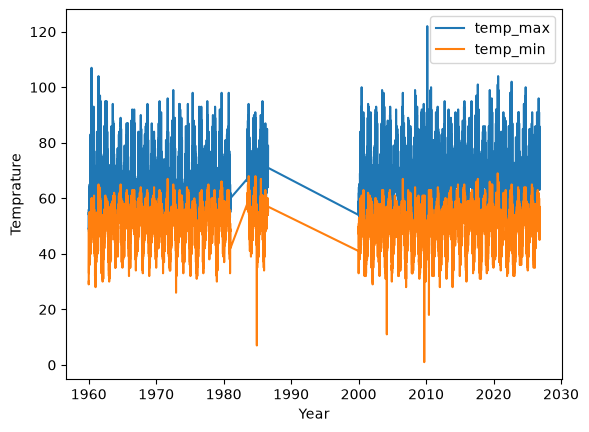

In [35]:
plt.plot(core_weather[['temp_max', 'temp_min']])
plt.xlabel('Year')
plt.ylabel('Temprature')
plt.legend(['temp_max', 'temp_min'])

In [36]:
core_weather.index.year.value_counts().sort_index()

DATE
1960    366
1961    365
1962    365
1963    365
1964    366
1965    365
1966    365
1967    365
1968    366
1969    365
1970    365
1971    365
1972    366
1973    365
1974    365
1975    365
1976    366
1977    365
1978    365
1979    365
1980    366
1983    184
1984    366
1985    365
1986    212
2000    365
2001    365
2002    365
2003    365
2004    365
2005    365
2006    365
2007    365
2008    366
2009    365
2010    365
2011    360
2012    365
2013    364
2014    365
2015    365
2016    366
2017    365
2018    365
2019    362
2020    363
2021    364
2022    361
2023    365
2024    366
2025    365
2026    304
Name: count, dtype: int64

In [37]:
core_weather.columns

Index(['precip', 'temp_max', 'temp_min'], dtype='str')

Text(0, 0.5, 'Precipitation')

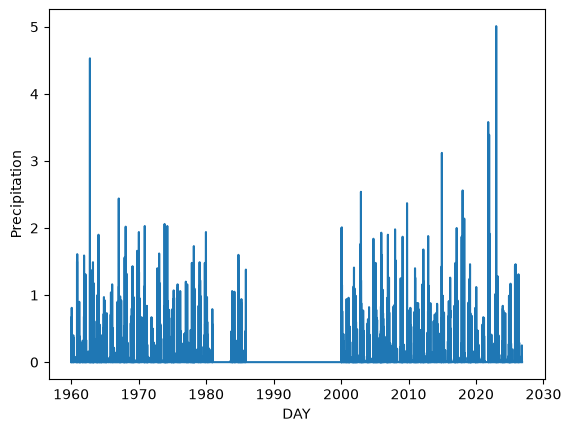

In [38]:
plt.plot(core_weather['precip'])
plt.xlabel('DAY')
plt.ylabel('Precipitation')

In [39]:
core_weather.groupby(core_weather.index.year).sum()

,precip,temp_max,temp_min
DATE,,,
1960,14.01,24135.0,17973.0
1961,13.87,24202.0,17819.0
1962,22.47,23785.0,17880.0
1963,19.11,23470.0,18237.0
1964,16.83,23013.0,18637.0
1965,16.32,23181.0,18715.0
1966,13.11,23680.0,18991.0
1967,23.98,23433.0,18668.0
1968,17.19,23634.0,18859.0


Text(0, 0.5, 'Actual Precipitation')

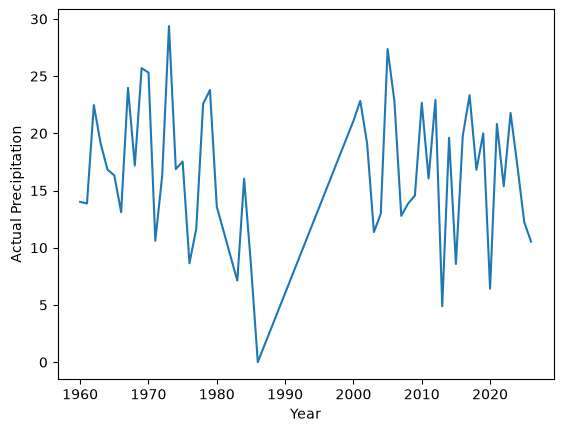

In [40]:
core_weather.groupby(core_weather.index.year)['precip'].sum().plot()
plt.xlabel('Year')
plt.ylabel('Actual Precipitation')

In [41]:
core_weather['target'] = core_weather.shift(-1)['temp_max']

In [42]:
core_weather

,precip,temp_max,temp_min,target
DATE,,,,
1960-01-01,0.0,49.0,30.0,49.0
1960-01-02,0.0,49.0,29.0,54.0
1960-01-03,0.0,54.0,35.0,54.0
1960-01-04,0.0,54.0,36.0,55.0
1960-01-05,0.0,55.0,33.0,53.0
...,...,...,...,...
2026-10-27,0.0,65.0,48.0,70.0
2026-10-28,0.0,70.0,45.0,68.0
2026-10-29,0.0,68.0,47.0,66.0


In [43]:
len(core_weather)

18579

In [44]:
core_weather = core_weather.iloc[:-1,:].copy()

In [45]:
core_weather.tail()

,precip,temp_max,temp_min,target
DATE,,,,
2026-10-26,0.0,68.0,57.0,65.0
2026-10-27,0.0,65.0,48.0,70.0
2026-10-28,0.0,70.0,45.0,68.0
2026-10-29,0.0,68.0,47.0,66.0
2026-10-30,0.0,66.0,52.0,65.0


In [46]:
reg = Ridge(alpha = 0.1)

In [47]:
predictors = ["precip","temp_max","temp_min"]

In [48]:
train = core_weather.loc[:"2020-12-31",:]
test = core_weather.loc["2021-01-01":,:]

In [49]:
train

,precip,temp_max,temp_min,target
DATE,,,,
1960-01-01,0.00,49.0,30.0,49.0
1960-01-02,0.00,49.0,29.0,54.0
1960-01-03,0.00,54.0,35.0,54.0
1960-01-04,0.00,54.0,36.0,55.0
1960-01-05,0.00,55.0,33.0,53.0
...,...,...,...,...
2020-12-27,0.00,63.0,44.0,61.0
2020-12-28,0.10,61.0,42.0,60.0
2020-12-29,0.00,60.0,39.0,56.0


In [50]:
test

,precip,temp_max,temp_min,target
DATE,,,,
2021-01-01,0.00,60.0,40.0,57.0
2021-01-02,0.14,57.0,51.0,56.0
2021-01-03,0.00,56.0,49.0,62.0
2021-01-04,0.36,62.0,46.0,59.0
2021-01-05,0.00,59.0,42.0,59.0
...,...,...,...,...
2026-10-26,0.00,68.0,57.0,65.0
2026-10-27,0.00,65.0,48.0,70.0
2026-10-28,0.00,70.0,45.0,68.0


In [51]:
model = reg.fit(train[predictors],train['target'])

In [52]:
model

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [53]:
predictions = model.predict(test[predictors])

In [54]:
mean_absolute_error(test['target'], predictions)

3.3238044704468193

In [55]:
combined = pd.concat([test['target'],pd.Series(predictions, index=test.index)], axis=1)
combined.columns = ['actual','predictions']

In [56]:
combined

,actual,predictions
DATE,,
2021-01-01,57.0,59.806026
2021-01-02,56.0,59.314125
2021-01-03,62.0,58.543303
2021-01-04,59.0,61.530629
2021-01-05,59.0,59.445358
...,...,...
2026-10-26,65.0,68.629769
2026-10-27,70.0,64.848493
2026-10-28,68.0,67.911496


Text(0, 0.5, 'Tomorrow Temprature')

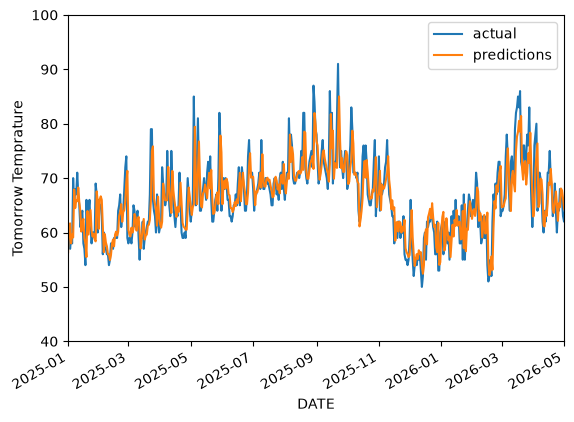

In [57]:
combined.plot()
plt.xlim('2025-01-01', '2026-05-01')
plt.ylim(40,100)
plt.ylabel('Tomorrow Temprature')

In [58]:
def create_predictions(predictors, core_weather, reg):
    train = core_weather.loc[:"2020-12-31",:]
    test = core_weather.loc["2021-01-01":,:]

    reg.fit(train[predictors], train["target"])
    predictions = reg.predict(test[predictors])

    error = mean_absolute_error(test["target"], predictions)
    combined = pd.concat([test["target"],pd.Series(predictions, index=test.index)], axis=1)
    
    #combined = core_weather.concat([test["target"], pd.Series(predictions, index=test.index)], axis=1)
    combined.columns = ["actual", "predictions"]
    return error, combined

In [59]:
core_weather["month_max"] = core_weather["temp_max"].rolling(30).mean()

core_weather["month_day_max"] = core_weather["month_max"] / core_weather["temp_max"]

core_weather["max_min"] = core_weather["temp_max"] / core_weather["temp_min"] # ration between max & min temp

In [60]:
core_weather

,precip,temp_max,temp_min,target,month_max,month_day_max,max_min
DATE,,,,,,,
1960-01-01,0.0,49.0,30.0,49.0,NaN,NaN,1.633333
1960-01-02,0.0,49.0,29.0,54.0,NaN,NaN,1.689655
1960-01-03,0.0,54.0,35.0,54.0,NaN,NaN,1.542857
1960-01-04,0.0,54.0,36.0,55.0,NaN,NaN,1.500000
1960-01-05,0.0,55.0,33.0,53.0,NaN,NaN,1.666667
...,...,...,...,...,...,...,...
2026-10-26,0.0,68.0,57.0,65.0,74.633333,1.097549,1.192982
2026-10-27,0.0,65.0,48.0,70.0,74.633333,1.148205,1.354167
2026-10-28,0.0,70.0,45.0,68.0,74.633333,1.066190,1.555556


In [61]:
core_weather.columns

Index(['precip', 'temp_max', 'temp_min', 'target', 'month_max',
       'month_day_max', 'max_min'],
      dtype='str')

In [62]:
core_weather = core_weather.iloc[30:,:].copy()

In [63]:
train['target'].isnull().sum()

np.int64(0)

In [64]:
core_weather[predictors].isnull().sum()

precip      0
temp_max    0
temp_min    0
dtype: int64

In [65]:
core_weather = core_weather.replace([np.inf, -np.inf], np.nan) # replacing the inf, -inf with Nan

In [66]:
core_weather[["month_day_max", "max_min"]].isnull().sum()

month_day_max    0
max_min          0
dtype: int64

In [67]:
core_weather.loc[core_weather[["month_day_max", "max_min"]].isna().any(axis=1), ["temp_max", "temp_min", "month_max", "month_day_max", "max_min"]] # finding the rows that at least has one NaN

,temp_max,temp_min,month_max,month_day_max,max_min
DATE,,,,,


In [68]:
(core_weather['temp_max'] == 0).sum()

np.int64(0)

In [69]:
(core_weather['temp_min'] == 0).sum()

np.int64(0)

In [70]:
core_weather.loc[core_weather['temp_max'] == 0, ["temp_max", "temp_min"]]

,temp_max,temp_min
DATE,,


In [71]:
weather.loc[["2019-04-18", "2019-04-21", "2019-04-22"],
    ["TMAX", "TMIN"]]

,TMAX,TMIN
DATE,,
2019-04-18,NaN,50.0
2019-04-21,NaN,52.0
2019-04-22,NaN,50.0


In [72]:
train[predictors].isnull().sum()

precip      0
temp_max    0
temp_min    0
dtype: int64

In [73]:
predictors = ['precip', 'temp_max', 'temp_min', 'month_max', "month_day_max", "max_min"]

error, combined = create_predictions(predictors, core_weather, reg)

In [74]:
error

3.2662437159826254

In [75]:
pd.Series(reg.coef_, index=predictors)

precip           -1.422706
temp_max          0.384171
temp_min          0.088792
month_max         0.493988
month_day_max   -18.575833
max_min           0.101194
dtype: float64

In [76]:
reg.coef_

array([ -1.42270641,   0.38417093,   0.08879176,   0.49398817,
       -18.57583341,   0.10119384])

In [77]:
combined.index

DatetimeIndex(['2021-01-01', '2021-01-02', '2021-01-03', '2021-01-04',
               '2021-01-05', '2021-01-06', '2021-01-07', '2021-01-08',
               '2021-01-09', '2021-01-10',
               ...
               '2026-10-21', '2026-10-22', '2026-10-23', '2026-10-24',
               '2026-10-25', '2026-10-26', '2026-10-27', '2026-10-28',
               '2026-10-29', '2026-10-30'],
              dtype='datetime64[us]', name='DATE', length=2124, freq=None)

Text(0, 0.5, 'Tomorrow Temprature')

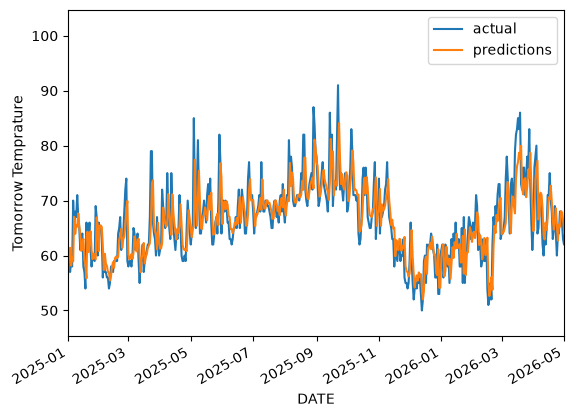

In [78]:
combined.plot()
plt.xlim('2025-01-01', '2026-05-01')
plt.ylabel("Tomorrow Temprature")

In [79]:
core_weather['monthly_avg'] = core_weather['temp_max'].groupby(core_weather.index.month).transform(lambda x: x.expanding(1).mean())

In [80]:
core_weather

,precip,temp_max,temp_min,target,month_max,month_day_max,max_min,monthly_avg
DATE,,,,,,,,
1960-01-31,0.00,59.0,46.0,62.0,55.566667,0.941808,1.282609,59.000000
1960-02-01,0.81,62.0,51.0,59.0,56.000000,0.903226,1.215686,62.000000
1960-02-02,0.00,59.0,43.0,59.0,56.166667,0.951977,1.372093,60.500000
1960-02-03,0.20,59.0,47.0,60.0,56.333333,0.954802,1.255319,60.000000
1960-02-04,0.16,60.0,42.0,60.0,56.500000,0.941667,1.428571,60.000000
...,...,...,...,...,...,...,...,...
2026-10-26,0.00,68.0,57.0,65.0,74.633333,1.097549,1.192982,70.817314
2026-10-27,0.00,65.0,48.0,70.0,74.633333,1.148205,1.354167,70.813613
2026-10-28,0.00,70.0,45.0,68.0,74.633333,1.066190,1.555556,70.813096


In [81]:
core_weather['day_of_year_avg'] = core_weather['temp_max'].groupby(core_weather.index.day_of_year).transform(lambda x: x.expanding(1).mean())

In [82]:
core_weather.columns

Index(['precip', 'temp_max', 'temp_min', 'target', 'month_max',
       'month_day_max', 'max_min', 'monthly_avg', 'day_of_year_avg'],
      dtype='str')

In [83]:
predictors = ['precip', 'temp_max', 'temp_min', 'month_max',
       'month_day_max', 'max_min', 'monthly_avg', 'day_of_year_avg']

In [84]:
error, combined = create_predictions(predictors, core_weather, reg)

In [85]:
error

3.2477011575510257

In [86]:
pd.Series(reg.coef_, index=predictors)

precip             -0.909153
temp_max            0.397191
temp_min            0.030921
month_max           0.340043
month_day_max     -16.211788
max_min             0.049137
monthly_avg         0.143306
day_of_year_avg     0.081105
dtype: float64

In [87]:
reg.coef_

array([ -0.90915276,   0.39719116,   0.03092132,   0.34004347,
       -16.21178816,   0.04913734,   0.14330616,   0.08110483])

In [88]:
core_weather.corr()['target']

precip            -0.207677
temp_max           0.820957
temp_min           0.594299
target             1.000000
month_max          0.687495
month_day_max     -0.420053
max_min            0.045501
monthly_avg        0.688893
day_of_year_avg    0.711219
Name: target, dtype: float64

In [89]:
combined['diff'] = (combined['actual'] - combined['predictions']).abs()

In [90]:
combined.sort_values('diff', ascending=False).head()

,actual,predictions,diff
DATE,,,
2022-06-20,98.0,76.760840,21.239160
2025-05-04,85.0,66.231176,18.768824
2024-09-29,90.0,72.322795,17.677205
2024-07-01,93.0,75.697300,17.302700
2026-07-20,88.0,71.325226,16.674774
